In [1]:
import copy
import time
import random

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
import torch_fidelity
from torch.utils.data import TensorDataset, DataLoader
from torchvision.utils import make_grid
from sklearn.model_selection import train_test_split

In [2]:
SEED    = 42
BATCH   = 128
ZDIM    = 64           # latent size of AE / Sparse AE / VAE / MLP feature
NZ      = 100          # noise size of GAN / DCGAN
LAMBDA  = 5e-5         # sparsity weight (Sparse AE)
T       = 1000         # number of diffusion steps
N_FID   = 5000         # number of generated images used for FID


EPOCHS = dict(
    mlp=40,
    dec=40,
    ae=40,
    sae=40,
    vae=40,
    gan=40,
    dcgan=40,
    ddpm=40,
)

PATIENCE = dict(
    mlp=5,
    dec=5,
    ae=5,
    sae=5,
    vae=5,
    ddpm=10,
)

MIN_DELTA = 1e-3 # minimum improvement for early stopping

In [3]:
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def seed_all():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)


seed_all()

# 1. DATA

In [4]:
train_raw = torchvision.datasets.FashionMNIST(root="data", train=True, download=True)
test_raw = torchvision.datasets.FashionMNIST(root="data", train=False, download=True)

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.3MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 200kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.75MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 29.7MB/s]


In [5]:
X = torch.cat([train_raw.data, test_raw.data])
X = X.float() / 255
X = X.unsqueeze(1) # shape (70000, 1, 28, 28)
Y = torch.cat([train_raw.targets, test_raw.targets])

In [6]:
X_train, X_temp, Y_train, Y_temp = train_test_split(
    X, Y,
    test_size=0.2,
    random_state=SEED,
    stratify=Y
)

X_val, X_test, Y_val, Y_test = train_test_split(
    X_temp, Y_temp,
    test_size=0.5,
    random_state=SEED,
    stratify=Y_temp
)

In [7]:
train_loader = DataLoader(TensorDataset(X_train, Y_train), BATCH, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, Y_val), BATCH, shuffle=False)
test_loader = DataLoader(TensorDataset(X_test, Y_test), BATCH, shuffle=False)

print("train", len(X_train), "| val", len(X_val), "| test", len(X_test))

train 56000 | val 7000 | test 7000


# 2. METRICS

In [10]:
from torchmetrics import MeanSquaredError
from torchmetrics.image import (
    PeakSignalNoiseRatio,
    StructuralSimilarityIndexMeasure,
)
from torchmetrics.image.fid import FrechetInceptionDistance

mse_metric = MeanSquaredError().to(dev)
psnr_metric = PeakSignalNoiseRatio(data_range=1.0, dim=(1, 2, 3)).to(dev)
ssim_metric = StructuralSimilarityIndexMeasure(data_range=1.0).to(dev)
fid_metric = FrechetInceptionDistance(
    feature=2048,
    reset_real_features=False,
    normalize=True,
).to(dev)

@torch.no_grad()
def recon_metrics(recon_fn):
    """Test MSE / PSNR / SSIM between recon_fn(x) and the original x."""
    mse_metric.reset()
    psnr_metric.reset()
    ssim_metric.reset()

    for x, _ in test_loader:
        x = x.to(dev)
        x_rec = recon_fn(x).clamp(0, 1)

        mse_metric.update(x_rec, x)
        psnr_metric.update(x_rec, x)
        ssim_metric.update(x_rec, x)

    return dict(
        mse=mse_metric.compute().item(),
        psnr=psnr_metric.compute().item(),
        ssim=ssim_metric.compute().item(),
    )


@torch.no_grad()
def add_images_to_fid(images, real):
    """Feed images (N, 1, 28, 28) in 0..1 to the FID metric. real=True for real images."""
    for start in range(0, len(images), 250):
        batch = images[start:start + 250].to(dev).clamp(0, 1)
        batch = batch.repeat(1, 3, 1, 1) 
        fid_metric.update(batch, real=real)


def fid_of(fake_images):
    fid_metric.reset()
    add_images_to_fid(fake_images, real=False)
    return fid_metric.compute().item()


def latency_ms(fn, runs=20):
    """Average time in milliseconds for one call of fn() (= one batch of 64 images)."""
    with torch.no_grad():
        fn()                                       # warm-up
        torch.cuda.synchronize()
        start = time.perf_counter()
        for _ in range(runs):
            fn()
        torch.cuda.synchronize()
        elapsed = time.perf_counter() - start
    return elapsed / runs * 1000

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:01<00:00, 68.3MB/s]


# 3. MODELS

In [11]:
from torchvision.ops import MLP
from diffusers import UNet2DModel, DDPMScheduler
from functools import partial

class MLPClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 256)
        self.fc2 = nn.Linear(256, 64)
        self.fc3 = nn.Linear(64, 10)

    def features(self, x):
        x = x.flatten(1)
        h = F.relu(self.fc1(x))
        z = F.relu(self.fc2(h))
        return z

    def forward(self, x):
        z = self.features(x)
        return self.fc3(z)

class AE(nn.Module):
    def __init__(self, lam=0.0):
        super().__init__()
        self.lam = lam

        self.enc1 = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
        )
        self.enc2 = nn.Linear(256, ZDIM)
        self.dec = MLP(ZDIM, [256, 784])

    def encode(self, x):
        h = self.enc1(x)
        z = self.enc2(h)
        return z

    def decode(self, z):
        pixels = torch.sigmoid(self.dec(z))
        return pixels.view(-1, 1, 28, 28)

    def recon(self, x):
        z = self.encode(x)
        return self.decode(z)

    def loss(self, x):
        h = self.enc1(x)
        z = self.enc2(h)
        x_rec = self.decode(z)

        recon_loss = F.mse_loss(x_rec, x)
        sparsity_loss = h.abs().sum(dim=1).mean()
        return recon_loss + self.lam * sparsity_loss


class VAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = MLP(784, [512, 256, 2 * ZDIM])
        self.decoder = MLP(ZDIM, [256, 512, 784])

    def encode(self, x):
        output = self.encoder(x.flatten(1))
        mu, logvar = output.chunk(2, dim=1)
        return mu, logvar

    def decode(self, z):
        pixels = torch.sigmoid(self.decoder(z))
        return pixels.view(-1, 1, 28, 28)

    def recon(self, x):
        mu, _ = self.encode(x)
        return self.decode(mu)

    def loss(self, x):
        mu, logvar = self.encode(x)

        std = torch.exp(0.5 * logvar)
        z = mu + std * torch.randn_like(mu)

        logits = self.decoder(z).view(-1, 1, 28, 28)
        recon_loss = F.binary_cross_entropy_with_logits(logits, x, reduction="sum") / len(x)
        kl_loss = -0.5 * torch.sum(1 + logvar - mu ** 2 - logvar.exp()) / len(x)
        return recon_loss + kl_loss

leaky_relu = partial(nn.LeakyReLU, 0.2)

G_gan = nn.Sequential(
    MLP(NZ, [256, 512, 1024, 784], activation_layer=leaky_relu),
    nn.Tanh(),
    nn.Unflatten(1, (1, 28, 28)),
)

D_gan = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 1024),
    nn.LeakyReLU(0.2),
    nn.Dropout(0.3),
    nn.Linear(1024, 512),
    nn.LeakyReLU(0.2),
    nn.Dropout(0.3),
    nn.Linear(512, 256),
    nn.LeakyReLU(0.2),
    nn.Dropout(0.3),
    nn.Linear(256, 1),
)
G_gan = G_gan.to(dev)
D_gan = D_gan.to(dev)

G_dc = nn.Sequential(
    nn.Unflatten(1, (NZ, 1, 1)),
    nn.ConvTranspose2d(NZ, 256, 7, 1, 0, bias=False),
    nn.BatchNorm2d(256),
    nn.ReLU(),
    nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
    nn.BatchNorm2d(128),
    nn.ReLU(),
    nn.ConvTranspose2d(128, 1, 4, 2, 1),
    nn.Tanh(),
)
D_dc = nn.Sequential(
    nn.Conv2d(1, 64, 4, 2, 1),
    nn.LeakyReLU(0.2),
    nn.Conv2d(64, 128, 4, 2, 1, bias=False),
    nn.BatchNorm2d(128),
    nn.LeakyReLU(0.2),
    nn.Conv2d(128, 1, 7, 1, 0),
    nn.Flatten(),
)
G_dc = G_dc.to(dev)
D_dc = D_dc.to(dev)


def dcgan_init(module):
    is_conv = isinstance(module, (nn.Conv2d, nn.ConvTranspose2d))
    if is_conv:
        nn.init.normal_(module.weight, 0, 0.02)


G_dc.apply(dcgan_init)
D_dc.apply(dcgan_init)

unet = UNet2DModel(
    sample_size=28,
    in_channels=1,
    out_channels=1,
    layers_per_block=2,
    block_out_channels=(32, 64, 64),
    down_block_types=("DownBlock2D", "DownBlock2D", "DownBlock2D"),
    up_block_types=("UpBlock2D", "UpBlock2D", "UpBlock2D"),
).to(dev)

scheduler = DDPMScheduler(
    num_train_timesteps=T,
    beta_schedule="linear",
    beta_start=1e-4,
    beta_end=0.02,
)


@torch.no_grad()
def ddpm_sample(net, n, record=False):
    net.eval()
    x = torch.randn(n, 1, 28, 28, device=dev)
    snapshots = [x.clone()]

    for t in scheduler.timesteps:
        predicted_noise = net(x, t).sample
        x = scheduler.step(predicted_noise, t, x).prev_sample

        if record and t % 200 == 0:
            snapshots.append(x.clone())

    return x.clamp(-1, 1), snapshots

# 4. TRAINING

In [12]:
from tqdm.auto import tqdm


class EarlyStopping:
    def __init__(self, patience):
        self.patience = patience
        self.best = float("inf")
        self.wait = 0
        self.best_state = None
        self.best_epoch = 0

    def step(self, val, model, epoch):
        improved = val < self.best * (1 - MIN_DELTA)

        if improved:
            self.best = val
            self.wait = 0
            self.best_epoch = epoch
            self.best_state = copy.deepcopy(model.state_dict())
        else:
            self.wait += 1

        return self.wait >= self.patience

    def restore(self, model):
        model.load_state_dict(self.best_state)


def train_model(model, epochs, patience, name, lr=1e-3):
    print(f"========== {name} ==========")
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    hist = dict(train=[], val=[], time=[])
    early_stop = EarlyStopping(patience)

    for epoch in tqdm(range(epochs), desc="Epochs"):
        model.train()
        start = time.time()
        train_total = 0

        train_bar = tqdm(
            train_loader,
            desc=f"Train {epoch + 1}/{epochs}",
            leave=False
        )

        for x, _ in train_bar:
            x = x.to(dev)
            loss = model.loss(x)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            train_total += loss.item() * len(x)
            train_bar.set_postfix(loss=f"{loss.item():.4f}")

        hist["time"].append(time.time() - start)
        hist["train"].append(train_total / len(X_train))

        model.eval()
        val_total = 0

        val_bar = tqdm(
            val_loader,
            desc=f"Val {epoch + 1}/{epochs}",
            leave=False
        )

        with torch.no_grad():
            for x, _ in val_bar:
                x = x.to(dev)
                loss = model.loss(x)
                val_total += loss.item() * len(x)
                val_bar.set_postfix(loss=f"{loss.item():.4f}")

        val_loss = val_total / len(X_val)
        hist["val"].append(val_loss)

        tqdm.write(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train: {hist['train'][-1]:.4f} | "
            f"Val: {val_loss:.4f}"
        )

        should_stop = early_stop.step(val_loss, model, epoch + 1)

        if should_stop:
            tqdm.write(
                f"Early stopping at epoch {epoch + 1}, "
                f"best epoch: {early_stop.best_epoch}"
            )
            break

    early_stop.restore(model)
    hist["best_epoch"] = early_stop.best_epoch
    return hist


def train_mlp(model, epochs, patience, lr=1e-3):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    early_stop = EarlyStopping(patience)

    for epoch in tqdm(range(epochs), desc="Epochs"):
        # train
        model.train()

        train_bar = tqdm(
            train_loader,
            desc=f"Train {epoch + 1}/{epochs}",
            leave=False
        )

        
        for x, y in train_bar:
            x = x.to(dev)
            y = y.to(dev)
            loss = F.cross_entropy(model(x), y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            train_bar.set_postfix(loss=f"{loss.item():.4f}")

        # val
        model.eval()
        correct = 0

        val_bar = tqdm(
            val_loader,
            desc=f"Val {epoch + 1}/{epochs}",
            leave=False
        )


        with torch.no_grad():
            for x, y in val_bar:
                predictions = model(x.to(dev)).argmax(dim=1).cpu()
                correct += (predictions == y).sum().item()
                val_bar.set_postfix(accuracy=f"{correct / len(X_val):.4f}")
                
        val_accuracy = correct / len(X_val)

        should_stop = early_stop.step(1 - val_accuracy, model, epoch + 1)
        if should_stop:
            tqdm.write(f"MLP early stop at epoch {epoch + 1}, best epoch was {early_stop.best_epoch}")
            break

    early_stop.restore(model)


    model.eval()
    correct = 0
    with torch.no_grad():
        for x, y in test_loader:
            predictions = model(x.to(dev)).argmax(dim=1).cpu()
            correct += (predictions == y).sum().item()
    return correct / len(X_test)


def train_gan(G, D, epochs, name, lr=2e-4):
    print(f"========== {name} ==========")
    optimizer_G = torch.optim.Adam(G.parameters(), lr=lr, betas=(0.5, 0.999))
    optimizer_D = torch.optim.Adam(D.parameters(), lr=lr, betas=(0.5, 0.999))
    bce = nn.BCEWithLogitsLoss()
    hist = dict(g=[], d=[], time=[])

    for epoch in tqdm(range(epochs), desc="Epochs"):
        G.train()
        D.train()
        start = time.time()
        g_total = 0
        d_total = 0

        train_bar = tqdm(
            train_loader,
            desc=f"Train {epoch + 1}/{epochs}",
            leave=False
        )

        for x, _ in train_bar:
            x = x.to(dev) * 2 - 1
            n = len(x)

            real_labels = torch.ones(n, 1, device=dev)
            fake_labels = torch.zeros(n, 1, device=dev)

            noise = torch.randn(n, NZ, device=dev)
            fake_images = G(noise)

            d_loss_real = bce(D(x), real_labels)
            d_loss_fake = bce(D(fake_images.detach()), fake_labels)
            d_loss = d_loss_real + d_loss_fake

            optimizer_D.zero_grad()
            d_loss.backward()
            optimizer_D.step()

            g_loss = bce(D(fake_images), real_labels)

            optimizer_G.zero_grad()
            g_loss.backward()
            optimizer_G.step()

            g_total += g_loss.item() * n
            d_total += d_loss.item() * n

            train_bar.set_postfix(
                G=f"{g_loss.item():.4f}",
                D=f"{d_loss.item():.4f}"
            )

        hist["time"].append(time.time() - start)
        hist["g"].append(g_total / len(X_train))
        hist["d"].append(d_total / len(X_train))

        tqdm.write(
            f"Epoch {epoch + 1}/{epochs} | "
            f"G: {hist['g'][-1]:.4f} | "
            f"D: {hist['d'][-1]:.4f}"
        )

    return hist


@torch.no_grad()
def ddpm_val_loss(net):
    net.eval()
    generator = torch.Generator(device=dev).manual_seed(0)
    total = 0

    val_bar = tqdm(val_loader, desc="Validation", leave=False)

    for x, _ in val_bar:
        x = x.to(dev) * 2 - 1
        n = len(x)

        t = torch.randint(0, T, (n,), device=dev, generator=generator)
        noise = torch.randn(x.shape, device=dev, generator=generator)
        x_noisy = scheduler.add_noise(x, noise, t)

        predicted_noise = net(x_noisy, t).sample
        loss = F.mse_loss(predicted_noise, noise)

        total += loss.item() * n

        val_bar.set_postfix(loss=f"{loss.item():.4f}")

    return total / len(X_val)


def train_ddpm(net, epochs, patience, lr=2e-4):
    print(f"========== DDPM ==========")
    optimizer = torch.optim.Adam(net.parameters(), lr=lr)
    hist = dict(train=[], val=[], time=[])
    early_stop = EarlyStopping(patience)

    for epoch in tqdm(range(epochs), desc="Epochs"):
        net.train()
        start = time.time()
        train_total = 0

        train_bar = tqdm(
            train_loader,
            desc=f"Train {epoch + 1}/{epochs}",
            leave=False
        )

        for x, _ in train_bar:
            x = x.to(dev) * 2 - 1
            n = len(x)

            t = torch.randint(0, T, (n,), device=dev)
            noise = torch.randn_like(x)

            x_noisy = scheduler.add_noise(x, noise, t)

            predicted_noise = net(x_noisy, t).sample
            loss = F.mse_loss(predicted_noise, noise)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            train_total += loss.item() * n

            train_bar.set_postfix(loss=f"{loss.item():.4f}")

        hist["time"].append(time.time() - start)
        hist["train"].append(train_total / len(X_train))

        val_loss = ddpm_val_loss(net)
        hist["val"].append(val_loss)

        tqdm.write(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train: {hist['train'][-1]:.4f} | "
            f"Val: {val_loss:.4f}"
        )

        should_stop = early_stop.step(val_loss, net, epoch + 1)

        if should_stop:
            tqdm.write(
                f"Early stopping at epoch {epoch + 1}, "
                f"best epoch: {early_stop.best_epoch}"
            )
            break

    early_stop.restore(net)
    hist["best_epoch"] = early_stop.best_epoch
    return hist

# 5. TRAIN: MLP, Vanilla AE, frozen decoder

In [13]:
seed_all()
mlp = MLPClassifier().to(dev)
mlp_test_accuracy = train_mlp(mlp, EPOCHS["mlp"], PATIENCE["mlp"])
print(f"MLP test accuracy: {mlp_test_accuracy:.4f} | (atleast 0.88)")

print()


for parameter in mlp.parameters():
    parameter.requires_grad = False

seed_all()
ae = AE(lam=0.0).to(dev)
h_ae = train_model(ae, EPOCHS["ae"], PATIENCE["ae"], "Vanilla AE")
ae.eval()

print()

class FrozenDecoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = MLP(64, [256, 784])

    def decode(self, z):
        pixels = torch.sigmoid(self.net(z))
        return pixels.view(-1, 1, 28, 28)

    def recon(self, x):
        with torch.no_grad():
            z = mlp.features(x)
        return self.decode(z)

    def loss(self, x):
        return F.mse_loss(self.recon(x), x)


seed_all()
fdec = FrozenDecoder().to(dev)
h_fdec = train_model(fdec, EPOCHS["dec"], PATIENCE["dec"], "Frozen Decoder")
fdec.eval()

Epochs:   0%|          | 0/40 [00:00<?, ?it/s]

Train 1/40:   0%|          | 0/438 [00:00<?, ?it/s]

Val 1/40:   0%|          | 0/55 [00:00<?, ?it/s]

Train 2/40:   0%|          | 0/438 [00:00<?, ?it/s]

Val 2/40:   0%|          | 0/55 [00:00<?, ?it/s]

Train 3/40:   0%|          | 0/438 [00:00<?, ?it/s]

... (285 outputs left out)

Train 40/40:   0%|          | 0/438 [00:00<?, ?it/s]

Val 40/40:   0%|          | 0/55 [00:00<?, ?it/s]

Epoch 40/40 | Train: 0.0171 | Val: 0.0178


FrozenDecoder(
  (net): MLP(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.0, inplace=False)
    (3): Linear(in_features=256, out_features=784, bias=True)
    (4): Dropout(p=0.0, inplace=False)
  )
)

# 6. TRAIN: Sparse AE, VAE, GAN, DCGAN, DDPM

In [14]:
seed_all()
sae = AE(lam=LAMBDA).to(dev)
h_sae = train_model(sae, EPOCHS["sae"], PATIENCE["sae"], "Sparse AE")
sae.eval()

print()

seed_all()
vae = VAE().to(dev)
h_vae = train_model(vae, EPOCHS["vae"], PATIENCE["vae"], "VAE")
vae.eval()

print()

seed_all()
h_gan = train_gan(G_gan, D_gan, EPOCHS["gan"], "GAN")
G_gan.eval()

print()

seed_all()
h_dc = train_gan(G_dc, D_dc, EPOCHS["dcgan"], "DCGAN")
G_dc.eval()

print()

seed_all()
h_ddpm = train_ddpm(unet, EPOCHS["ddpm"], PATIENCE["ddpm"])
unet.eval()

========== Sparse AE ==========


Epochs:   0%|          | 0/40 [00:00<?, ?it/s]

Train 1/40:   0%|          | 0/438 [00:00<?, ?it/s]

Val 1/40:   0%|          | 0/55 [00:00<?, ?it/s]

Epoch 1/40 | Train: 0.0374 | Val: 0.0226


Train 2/40:   0%|          | 0/438 [00:00<?, ?it/s]

... (511 outputs left out)

Train 40/40:   0%|          | 0/438 [00:00<?, ?it/s]

Validation:   0%|          | 0/55 [00:00<?, ?it/s]

Epoch 40/40 | Train: 0.0371 | Val: 0.0352


UNet2DModel(
  (conv_in): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (time_proj): Timesteps()
  (time_embedding): TimestepEmbedding(
    (linear_1): Linear(in_features=32, out_features=128, bias=True)
    (act): SiLU()
    (linear_2): Linear(in_features=128, out_features=128, bias=True)
  )
  (down_blocks): ModuleList(
    (0): DownBlock2D(
      (resnets): ModuleList(
        (0-1): 2 x ResnetBlock2D(
          (norm1): GroupNorm(32, 32, eps=1e-05, affine=True, bias=True)
          (conv1): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (time_emb_proj): Linear(in_features=128, out_features=32, bias=True)
          (norm2): GroupNorm(32, 32, eps=1e-05, affine=True, bias=True)
          (dropout): Dropout(p=0.0, inplace=False)
          (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (nonlinearity): SiLU()
        )
      )
      (downsamplers): ModuleList(
        (0): Downsample2D(
          (con

# 7. Bagian II: Tahap 2, 3, 5

In [15]:
W1 = mlp.fc1.weight
W2 = mlp.fc2.weight
W3 = mlp.fc3.weight

# tahap 2
onehot = torch.eye(10, device=dev)
z_hat = F.relu(onehot @ W3)
h1_hat = F.relu(z_hat @ W2)
x_from_class = torch.sigmoid(h1_hat @ W1).view(-1, 1, 28, 28)


# tahap 3
def transpose_recon(x):
    z = mlp.features(x)
    h1 = F.relu(z @ W2)
    x_hat = torch.sigmoid(h1 @ W1)
    return x_hat.view(-1, 1, 28, 28)


# tahap 5
with torch.no_grad():
    z_list = []
    for x, _ in test_loader:
        z_list.append(mlp.features(x.to(dev)))
    z_all = torch.cat(z_list)

    z_mean = z_all.mean(dim=0)
    z_std = z_all.std(dim=0)

    seed_all()
    z_random = z_mean + z_std * torch.randn(N_FID, 64, device=dev)
    mlp_samples = fdec.decode(z_random).cpu()

metrics_transpose = recon_metrics(transpose_recon)
metrics_frozen_decoder = recon_metrics(fdec.recon)
metrics_ae = recon_metrics(ae.recon)

print("Transposed weights (stage 3):", metrics_transpose)
print("Frozen z_MLP decoder (stage 4):", metrics_frozen_decoder)
print("Vanilla AE:", metrics_ae)

Transposed weights (stage 3): {'mse': 0.2954690456390381, 'psnr': 5.342807769775391, 'ssim': 0.050332266837358475}
Frozen z_MLP decoder (stage 4): {'mse': 0.017452040687203407, 'psnr': 18.39319610595703, 'ssim': 0.7118105888366699}
Vanilla AE: {'mse': 0.006216069217771292, 'psnr': 23.213878631591797, 'ssim': 0.8702381253242493}


# 8. EVAL

In [16]:
metrics_sae = recon_metrics(sae.recon)
metrics_vae = recon_metrics(vae.recon)

@torch.no_grad()
def gen_vae(n):
    z = torch.randn(n, ZDIM, device=dev)
    return vae.decode(z)


@torch.no_grad()
def gen_gan(n):
    noise = torch.randn(n, NZ, device=dev)
    return (G_gan(noise) + 1) / 2


@torch.no_grad()
def gen_dc(n):
    noise = torch.randn(n, NZ, device=dev)
    return (G_dc(noise) + 1) / 2


def gen_ddpm(n):
    images, _ = ddpm_sample(unet, n)
    return (images + 1) / 2


add_images_to_fid(X_test, real=True)

generators = [
    ("VAE", gen_vae, 1000),
    ("GAN", gen_gan, 1000),
    ("DCGAN", gen_dc, 1000),
    ("DDPM", gen_ddpm, 500),
]

fid = {}
for name, gen_fn, batch_size in generators:
    seed_all()
    batches = []
    for _ in range(N_FID // batch_size):
        batches.append(gen_fn(batch_size).cpu())
    fake_images = torch.cat(batches)

    fid[name] = fid_of(fake_images)
    print(f"FID {name}: {fid[name]:.2f}")

fid["MLP sampling"] = fid_of(mlp_samples)
print(f"FID MLP sampling: {fid['MLP sampling']:.2f}")

x64 = X_test[:64].to(dev)


def run_ae():
    return ae.recon(x64)


def run_sae():
    return sae.recon(x64)


def run_vae():
    return gen_vae(64)


def run_gan():
    return gen_gan(64)


def run_dc():
    return gen_dc(64)


def run_ddpm():
    return gen_ddpm(64)


latency = dict(
    AE=latency_ms(run_ae),
    SAE=latency_ms(run_sae),
    VAE=latency_ms(run_vae),
    GAN=latency_ms(run_gan),
    DCGAN=latency_ms(run_dc),
    DDPM=latency_ms(run_ddpm, runs=2),
)
print(latency)

FID VAE: 59.07
FID GAN: 109.28
FID DCGAN: 21.15
FID DDPM: 13.92
FID MLP sampling: 140.31
{'AE': 0.259471150002355, 'SAE': 0.24574925000706568, 'VAE': 0.2484950000052777, 'GAN': 0.417928849992677, 'DCGAN': 3.4365837999757787, 'DDPM': 20374.74173549981}


# 9. RESULTS AND FIGURES

      Model Latent  Train s/epoch  Latency ms/64       MSE       PSNR      SSIM         FID  Epochs run Best epoch
 Vanilla AE     64       1.955687       0.259471  0.006216  23.213879  0.870238         N/A          40         40
  Sparse AE     64       1.995714       0.245749  0.007863  22.131687  0.839592         N/A          40         40
        VAE     64       2.506683       0.248495  0.013863  19.510458  0.764004   59.068901          38         33
Vanilla GAN    100       4.062800       0.417929       N/A        N/A       N/A  109.280983          40          -
      DCGAN    100      14.551309       3.436584       N/A        N/A       N/A   21.147537          40          -
       DDPM  28x28      49.411269   20374.741735       N/A        N/A       N/A   13.915387          40         40


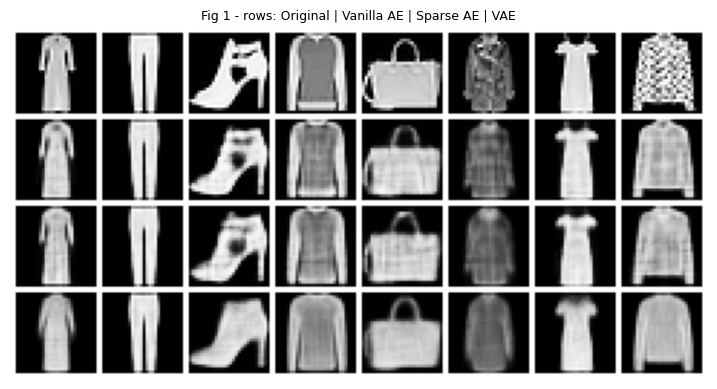

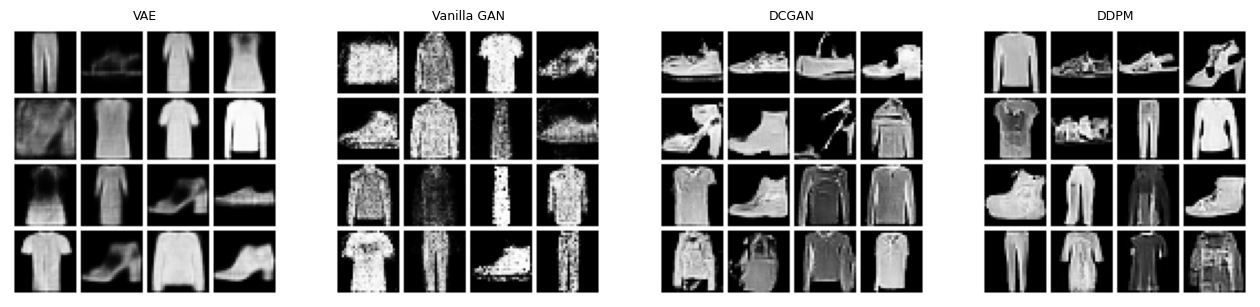

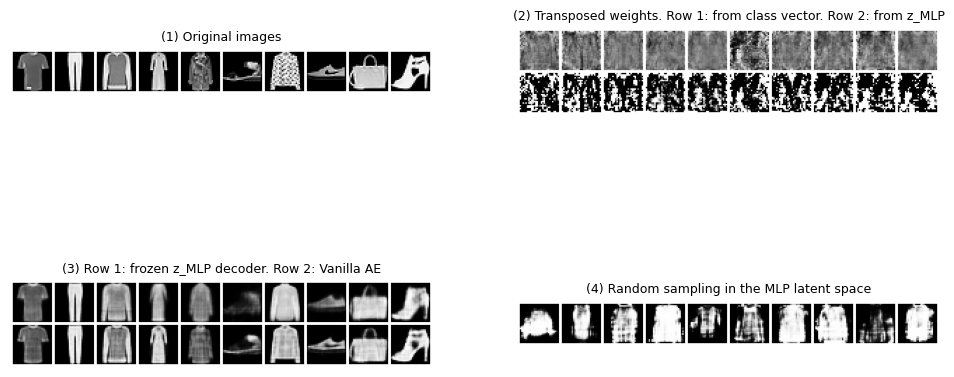

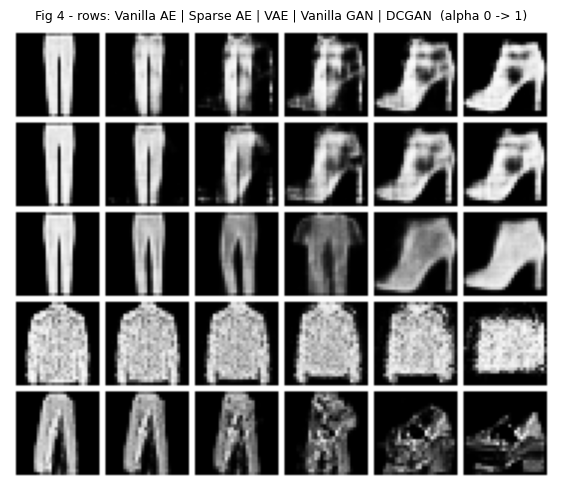

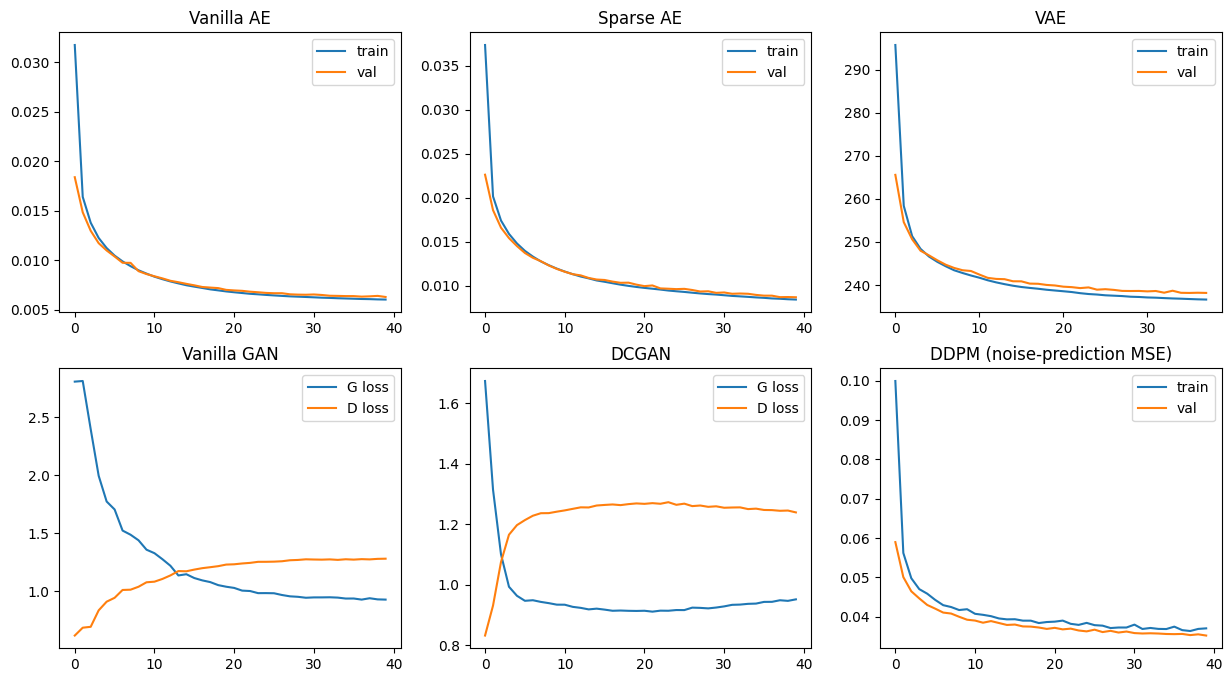

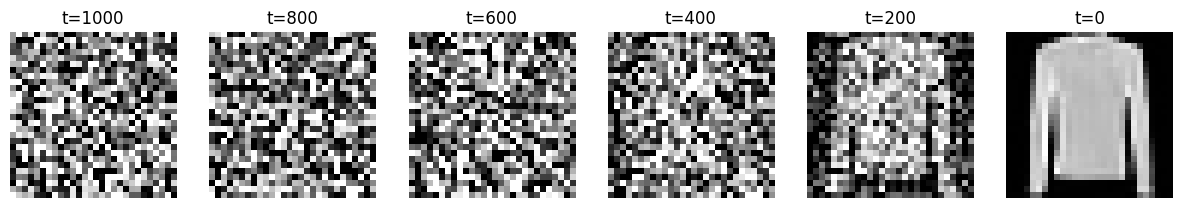

In [17]:
# ========================================================== RESULTS ==========================================================
def mean_epoch_time(hist):
    return float(np.mean(hist["time"]))


table = pd.DataFrame(
    [
        ["Vanilla AE", ZDIM, mean_epoch_time(h_ae), latency["AE"],
         metrics_ae["mse"], metrics_ae["psnr"], metrics_ae["ssim"], "N/A"],

        ["Sparse AE", ZDIM, mean_epoch_time(h_sae), latency["SAE"],
         metrics_sae["mse"], metrics_sae["psnr"], metrics_sae["ssim"], "N/A"],

        ["VAE", ZDIM, mean_epoch_time(h_vae), latency["VAE"],
         metrics_vae["mse"], metrics_vae["psnr"], metrics_vae["ssim"], fid["VAE"]],

        ["Vanilla GAN", NZ, mean_epoch_time(h_gan), latency["GAN"],
         "N/A", "N/A", "N/A", fid["GAN"]],

        ["DCGAN", NZ, mean_epoch_time(h_dc), latency["DCGAN"],
         "N/A", "N/A", "N/A", fid["DCGAN"]],

        ["DDPM", "28x28", mean_epoch_time(h_ddpm), latency["DDPM"],
         "N/A", "N/A", "N/A", fid["DDPM"]],
    ],
    columns=["Model", "Latent", "Train s/epoch", "Latency ms/64", "MSE", "PSNR", "SSIM", "FID"],
)

all_histories = [h_ae, h_sae, h_vae, h_gan, h_dc, h_ddpm]

epochs_run = []
best_epochs = []
for hist in all_histories:
    epochs_run.append(len(hist["time"]))
    best_epochs.append(hist.get("best_epoch", "-"))

table["Epochs run"] = epochs_run
table["Best epoch"] = best_epochs

print(table.to_string(index=False))
table.to_csv("results.csv", index=False)

# ========================================================== FIGURES ==========================================================

def show(ax, images, images_per_row, title):
    grid = make_grid(images.detach().cpu().clamp(0, 1), nrow=images_per_row, padding=2, pad_value=1)
    ax.imshow(grid.permute(1, 2, 0))
    ax.set_title(title, fontsize=9)
    ax.axis("off")


# ---- Figure 1: reconstruction (rows: original / Vanilla AE / Sparse AE / VAE) ----
x8 = X_test[:8].to(dev)
with torch.no_grad():
    rows = torch.cat([
        x8,
        ae.recon(x8),
        sae.recon(x8),
        vae.recon(x8),
    ])

fig, ax = plt.subplots(figsize=(9, 5))
show(ax, rows, 8, "Fig 1 - rows: Original | Vanilla AE | Sparse AE | VAE")
plt.savefig("fig1.png", dpi=200)
plt.show()

# ---- Figure 2: 4x4 random samples from each generative model ----
seed_all()
sample_sources = [
    (gen_vae, "VAE"),
    (gen_gan, "Vanilla GAN"),
    (gen_dc, "DCGAN"),
    (gen_ddpm, "DDPM"),
]

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, (gen_fn, name) in zip(axes, sample_sources):
    show(ax, gen_fn(16), 4, name)
plt.savefig("fig2.png", dpi=200)
plt.show()

# ---- Figure 3: why an MLP classifier cannot generate images (one test image per class) ----
first_index_per_class = []
for class_id in range(10):
    first_index = (Y_test == class_id).nonzero()[0].item()
    first_index_per_class.append(first_index)
x10 = X_test[first_index_per_class].to(dev)

with torch.no_grad():
    panel_transpose = torch.cat([x_from_class, transpose_recon(x10)])
    panel_decoders = torch.cat([fdec.recon(x10), ae.recon(x10)])
    panel_sampling = fdec.decode(z_random[:10])

fig, axes = plt.subplots(2, 2, figsize=(12, 6))
show(axes[0, 0], x10, 10, "(1) Original images")
show(axes[0, 1], panel_transpose, 10, "(2) Transposed weights. Row 1: from class vector. Row 2: from z_MLP")
show(axes[1, 0], panel_decoders, 10, "(3) Row 1: frozen z_MLP decoder. Row 2: Vanilla AE")
show(axes[1, 1], panel_sampling, 10, "(4) Random sampling in the MLP latent space")
plt.savefig("fig3.png", dpi=200)
plt.show()

# ---- Figure 4: linear interpolation between two latent points (Trouser -> Ankle boot) ----
alphas_list = [0, 0.2, 0.4, 0.6, 0.8, 1.0]
trouser_index = first_index_per_class[1]
boot_index = first_index_per_class[9]
img_a = X_test[trouser_index:trouser_index + 1].to(dev)
img_b = X_test[boot_index:boot_index + 1].to(dev)


def interpolate(z_a, z_b):
    """Return one row of latent vectors going from z_a (alpha=0) to z_b (alpha=1)."""
    points = []
    for alpha in alphas_list:
        points.append((1 - alpha) * z_a + alpha * z_b)
    return torch.cat(points)


seed_all()
noise_a = torch.randn(1, NZ, device=dev)
noise_b = torch.randn(1, NZ, device=dev)

with torch.no_grad():
    row_ae = ae.decode(interpolate(ae.encode(img_a), ae.encode(img_b)))
    row_sae = sae.decode(interpolate(sae.encode(img_a), sae.encode(img_b)))

    mu_a, _ = vae.encode(img_a)
    mu_b, _ = vae.encode(img_b)
    row_vae = vae.decode(interpolate(mu_a, mu_b))

    row_gan = (G_gan(interpolate(noise_a, noise_b)) + 1) / 2
    row_dc = (G_dc(interpolate(noise_a, noise_b)) + 1) / 2

    rows = torch.cat([row_ae, row_sae, row_vae, row_gan, row_dc])

fig, ax = plt.subplots(figsize=(7, 7))
show(ax, rows, 6, "Fig 4 - rows: Vanilla AE | Sparse AE | VAE | Vanilla GAN | DCGAN  (alpha 0 -> 1)")
plt.savefig("fig4.png", dpi=200)
plt.show()

# ---- Figure 5a: training curves ----
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

autoencoder_curves = [
    (axes[0, 0], h_ae, "Vanilla AE"),
    (axes[0, 1], h_sae, "Sparse AE"),
    (axes[0, 2], h_vae, "VAE"),
]
for ax, hist, name in autoencoder_curves:
    ax.plot(hist["train"], label="train")
    ax.plot(hist["val"], label="val")
    ax.set_title(name)
    ax.legend()

gan_curves = [
    (axes[1, 0], h_gan, "Vanilla GAN"),
    (axes[1, 1], h_dc, "DCGAN"),
]
for ax, hist, name in gan_curves:
    ax.plot(hist["g"], label="G loss")
    ax.plot(hist["d"], label="D loss")
    ax.set_title(name)
    ax.legend()

axes[1, 2].plot(h_ddpm["train"], label="train")
axes[1, 2].plot(h_ddpm["val"], label="val")
axes[1, 2].set_title("DDPM (noise-prediction MSE)")
axes[1, 2].legend()

plt.savefig("fig5a_curves.png", dpi=200)
plt.show()

# ---- Figure 5b: DDPM reverse process, from pure noise to an image ----
seed_all()
_, snapshots = ddpm_sample(unet, 1, record=True)
snapshot_steps = [T, 800, 600, 400, 200, 0]

fig, axes = plt.subplots(1, len(snapshots), figsize=(15, 3))
for ax, snapshot, step in zip(axes, snapshots, snapshot_steps):
    image = (snapshot[0, 0] + 1) / 2
    ax.imshow(image.clamp(0, 1).cpu(), cmap="gray")
    ax.set_title(f"t={step}")
    ax.axis("off")
plt.savefig("fig5b_ddpm_trajectory.png", dpi=200)
plt.show()